# BRD4-BD2 — Executed validation-derived errors

20 repeated scaffold development splits, 2,520 out-of-fold prediction occurrences. This is a post-processing notebook executed on actual fold predictions. Similarity threshold 0.30 is a structural screening criterion, not a validated prediction-interval guarantee.

In [1]:
import pandas as pd,numpy as np
from scipy.stats import spearmanr
from pathlib import Path
src=Path("/mnt/data/BRD4_BD2_AD_CALIBRATION/development_repeated_scaffold_oof_predictions.csv")
d=pd.read_csv(src)
d["abs_error"]=(d.predicted_pIC50-d.observed_pIC50).abs()
assert len(d)==2520 and d.repeat.nunique()==20
print("Prediction occurrences:",len(d),"Scaffold repeats:",d.repeat.nunique(),"Unique compounds:",d.molecule_chembl_ids.nunique())
print("Spearman similarity–abs error:",round(spearmanr(d.nearest_fold_training_tanimoto,d.abs_error).statistic,3))

Prediction occurrences: 2520 Scaffold repeats: 20 Unique compounds: 587
Spearman similarity–abs error: -0.346


## Similarity-bin errors (not cumulative threshold MAE)

In [2]:
edges=[0,.2,.3,.4,.5,.6,.7,.8,.9,1.00001]
d["similarity_bin"]=pd.cut(d.nearest_fold_training_tanimoto,edges,right=False)
summary=d.groupby("similarity_bin",observed=True).agg(n=("abs_error","size"),MAE=("abs_error","mean"),RMSE=("abs_error",lambda v:np.sqrt(np.mean(v*v)))).reset_index()
print(summary.to_string(index=False,float_format=lambda x:f"{x:.3f}"))

similarity_bin   n   MAE  RMSE
    [0.0, 0.2)  15 0.357 0.461
    [0.2, 0.3)  62 0.900 1.021
    [0.3, 0.4)  62 0.891 0.995
    [0.4, 0.5) 131 0.718 0.861
    [0.5, 0.6) 253 0.899 1.086
    [0.6, 0.7) 514 0.580 0.706
    [0.7, 0.8) 887 0.490 0.618
    [0.8, 0.9) 425 0.372 0.501
    [0.9, 1.0) 171 0.415 0.630


## Coverage and accuracy at AD cutoffs

In [3]:
rows=[]
for t in [.2,.3,.35,.4,.5,.6,.7]:
 sub=d[d.nearest_fold_training_tanimoto>=t]
 rows.append({"cutoff":t,"n":len(sub),"coverage":len(sub)/len(d),"MAE":sub.abs_error.mean(),"RMSE":np.sqrt((sub.abs_error**2).mean())})
thresholds=pd.DataFrame(rows)
print(thresholds.to_string(index=False,float_format=lambda v:f"{v:.3f}"))

 cutoff    n  coverage   MAE  RMSE
  0.200 2505     0.994 0.557 0.718
  0.300 2443     0.969 0.548 0.709
  0.350 2416     0.959 0.543 0.704
  0.400 2381     0.945 0.539 0.700
  0.500 2250     0.893 0.529 0.689
  0.600 1997     0.792 0.482 0.621
  0.700 1483     0.588 0.448 0.589


## Figure — validation-derived error vs similarity

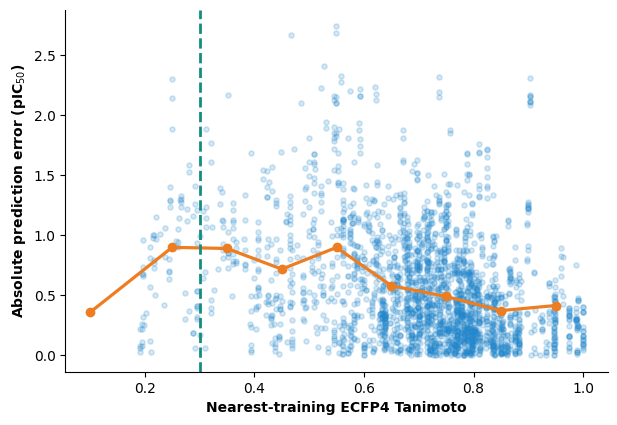

In [4]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,4.7))
ax.scatter(d.nearest_fold_training_tanimoto,d.abs_error,s=14,color="#2387cc",alpha=.20,rasterized=True)
centers=[b.mid for b in summary.similarity_bin]
ax.plot(centers,summary.MAE,color="#ed7d20",marker="o",lw=2.3)
ax.axvline(.3,color="#158c80",ls="--",lw=2)
ax.set_xlabel("Nearest-training ECFP4 Tanimoto",fontweight="bold");ax.set_ylabel("Absolute prediction error (pIC$_{50}$)",fontweight="bold")
ax.spines["top"].set_visible(False);ax.spines["right"].set_visible(False);plt.show()